# TP3 – Situação de Aprendizagem: **SENTINEL-AI**
## Classificação Avançada: Distâncias (kNN), Margens Máximas (SVM) e Probabilidades (Naive Bayes)

**Disciplina:** Aprendizagem de Máquina – SENAI-MG 2026/2

**Alunos: Mário Cezar Gouveia de Souza e Marcos Júnio dos Santos**

**Objetivo:** construir e auditar uma esteira de classificação supervisionada para uma fintech, decidindo se uma proposta de crédito é **Risco Aceitável / Baixo Risco (Classe 0)** ou **Risco Crítico / Inadimplência Potencial (Classe 1)**, comparando três famílias de algoritmos:

| Família | Algoritmo | Ideia central |
|---|---|---|
| Instâncias e distância | kNN | Vota com os K vizinhos mais próximos |
| Margens máximas | SVM (linear e RBF) | Hiperplano que separa as classes com a maior margem |
| Probabilidade condicional | Naive Bayes (Gaussiano) | Teorema de Bayes + independência entre atributos |

Como os erros têm **custos assimétricos** (conceder crédito a um inadimplente gera prejuízo direto; recusar um bom pagador gera custo de oportunidade), a análise dá atenção especial às métricas da **Classe 1**.

## 01. Ingestão dos dados

Código de ingestão obrigatório do enunciado (dataset público *Statlog German Credit*).

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

plt.rcParams["figure.dpi"] = 100

# Carregamento do dataset público
url_dados = "https://raw.githubusercontent.com/selva86/datasets/master/GermanCredit.csv"
df_raw = pd.read_csv(url_dados)
print(f"Dimensões do arquivo original: {df_raw.shape}")
print("Colunas disponíveis:", list(df_raw.columns))

Dimensões do arquivo original: (1000, 21)
Colunas disponíveis: ['status', 'duration', 'credit_history', 'purpose', 'amount', 'savings', 'employment_duration', 'installment_rate', 'personal_status_sex', 'other_debtors', 'present_residence', 'property', 'age', 'other_installment_plans', 'housing', 'number_credits', 'job', 'people_liable', 'telephone', 'foreign_worker', 'credit_risk']


### 02. Compatibilização das colunas

Ao executar o código de ingestão, verificou-se que a versão atual do arquivo `GermanCredit.csv` no link indicado **não contém as colunas com os nomes do enunciado** (`Duration`, `Amount`, `Age`, `InstallmentRatePercentage`, `CreditHistory.Critical`). O arquivo traz os mesmos atributos do *Statlog German Credit* com nomes em minúsculas (`duration`, `amount`, `age`, `installment_rate`) e o histórico de crédito em uma única coluna categórica (`credit_history`).

Para manter a especificação do trabalho sem alterar os dados:

* as colunas numéricas foram **renomeadas** para os nomes do enunciado;
* a variável alvo `CreditHistory.Critical` foi **derivada** de `credit_history`: vale **1** quando o histórico é `critical account/other credits existing` (histórico crítico) e **0** nos demais casos — exatamente a codificação *dummy* que dá origem à coluna `CreditHistory.Critical` na versão do dataset citada no enunciado.

Em seguida, a seleção de colunas obrigatória é aplicada sem modificações.

In [ ]:
# Compatibiliza os nomes das colunas com os do enunciado
df_raw = df_raw.rename(columns={
    "duration": "Duration",
    "amount": "Amount",
    "age": "Age",
    "installment_rate": "InstallmentRatePercentage",
})
# Variável alvo: 1 = Histórico Crítico / Inadimplente Potencial; 0 = Histórico Regular / Baixo Risco
df_raw["CreditHistory.Critical"] = (
    df_raw["credit_history"] == "critical account/other credits existing"
).astype(int)

# Seleção de colunas estruturadas para o benchmark (enunciado)
colunas_benchmark = [
    'Duration', 'Amount', 'Age', 'InstallmentRatePercentage',
    'savings', 'housing', 'CreditHistory.Critical'
]

df = df_raw[colunas_benchmark].copy()
print(f"Dimensões do dataset: {df.shape}")
df.head()

Dimensões do dataset: (1000, 7)


,Duration,Amount,Age,InstallmentRatePercentage,savings,housing,CreditHistory.Critical
0,6,1169,67,4,unknown/no savings account,own,1
1,48,5951,22,2,... < 100 DM,own,0
2,12,2096,49,2,... < 100 DM,own,1
3,42,7882,45,2,... < 100 DM,for free,0
4,24,4870,53,3,... < 100 DM,for free,0


### 03. Inspeção inicial
Verificação de tipos, valores ausentes, categorias e da distribuição da variável alvo.

In [ ]:
print(df.info())
print("\nValores ausentes por coluna:\n", df.isna().sum())
print("\nCategorias de 'savings':\n", df["savings"].value_counts())
print("\nCategorias de 'housing':\n", df["housing"].value_counts())
print("\nDistribuição da variável alvo:\n", df["CreditHistory.Critical"].value_counts(normalize=True).round(3))
df.describe().round(2)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   Duration                   1000 non-null   int64 
 1   Amount                     1000 non-null   int64 
 2   Age                        1000 non-null   int64 
 3   InstallmentRatePercentage  1000 non-null   int64 
 4   savings                    1000 non-null   object
 5   housing                    1000 non-null   object
 6   CreditHistory.Critical     1000 non-null   int64 
dtypes: int64(5), object(2)
memory usage: 54.8+ KB
None

Valores ausentes por coluna:
 Duration                     0
Amount                       0
Age                          0
InstallmentRatePercentage    0
savings                      0
housing                      0
CreditHistory.Critical       0
dtype: int64

Categorias de 'savings':
 savings
... < 100 DM                  603
unknown/no sav

,Duration,Amount,Age,InstallmentRatePercentage,CreditHistory.Critical
count,1000.00,1000.00,1000.00,1000.00,1000.00
mean,20.90,3271.26,35.55,2.97,0.29
std,12.06,2822.74,11.38,1.12,0.46
min,4.00,250.00,19.00,1.00,0.00
25%,12.00,1365.50,27.00,2.00,0.00
50%,18.00,2319.50,33.00,3.00,0.00
75%,24.00,3972.25,42.00,4.00,1.00
max,72.00,18424.00,75.00,4.00,1.00


**Leitura:** não há valores ausentes. A variável alvo é **desbalanceada**: cerca de **70,7%** dos clientes estão na Classe 0 e **29,3%** na Classe 1. Isso significa que um modelo "preguiçoso", que sempre responda Classe 0, já atinge cerca de 70% de acurácia sem identificar nenhum cliente de risco — por isso a acurácia sozinha não é uma boa métrica neste problema, e a análise vai se concentrar em **Precisão, Recall e F1 da Classe 1**. Os atributos numéricos têm escalas muito diferentes (`Amount` vai de centenas a quase 20 mil; `InstallmentRatePercentage` vai de 1 a 4), o que torna o escalonamento obrigatório.

---
## FASE 1 – Engenharia de Atributos, Escalonamento e Partição Estatística
### 1.1 Variáveis categóricas
* **`savings` → Ordinal Encoding**, respeitando a magnitude das reservas. A categoria `unknown/no savings account` (sem poupança ou desconhecida) foi posicionada no nível mais baixo (0), pois não comprova reserva financeira.
* **`housing` → One-Hot Encoding** com `drop_first=True` (a categoria `for free` vira a referência), evitando redundância e multicolinearidade (armadilha das *dummies*).

In [4]:
ordem_savings = [[
    "unknown/no savings account",   # 0 - sem poupança / desconhecida
    "... < 100 DM",                  # 1
    "100 <= ... < 500 DM",           # 2
    "500 <= ... < 1000 DM",          # 3
    "... >= 1000 DM",                # 4 - maiores reservas
]]
enc_ord = OrdinalEncoder(categories=ordem_savings)
df["savings"] = enc_ord.fit_transform(df[["savings"]]).astype(int)

# One-Hot Encoding de housing com descarte da primeira dummy
df = pd.get_dummies(df, columns=["housing"], drop_first=True, dtype=int)

X = df.drop(columns="CreditHistory.Critical")
y = df["CreditHistory.Critical"]
print("Atributos finais:", list(X.columns))
X.head()

Atributos finais: ['Duration', 'Amount', 'Age', 'InstallmentRatePercentage', 'savings', 'housing_own', 'housing_rent']


,Duration,Amount,Age,InstallmentRatePercentage,savings,housing_own,housing_rent
0,6,1169,67,4,0,1,0
1,48,5951,22,2,1,1,0
2,12,2096,49,2,1,1,0
3,42,7882,45,2,1,0,0
4,24,4870,53,3,1,0,0


### 1.2 Partição estatística (holdout 80/20) e escalonamento
A divisão é feita **antes** do escalonamento e o `StandardScaler` é ajustado (`fit`) **somente na base de treino**, sendo depois aplicado ao teste. Assim, média e desvio-padrão do teste não "vazam" para o treinamento (*data leakage*). O `stratify=y` mantém a mesma proporção de Classe 1 nos dois conjuntos, e `random_state=42` garante reprodutibilidade.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

num_cols = ["Duration", "Amount", "Age", "InstallmentRatePercentage"]
scaler = StandardScaler()
X_train = X_train.copy(); X_test = X_test.copy()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])   # ajuste apenas no treino
X_test[num_cols] = scaler.transform(X_test[num_cols])         # mesma transformação no teste

print(f"Treino: {X_train.shape} | Teste: {X_test.shape}")
print("Proporção da Classe 1 – treino: %.3f | teste: %.3f" % (y_train.mean(), y_test.mean()))
X_train[num_cols].describe().loc[["mean", "std"]].round(3)

Treino: (800, 7) | Teste: (200, 7)
Proporção da Classe 1 – treino: 0.292 | teste: 0.295


,Duration,Amount,Age,InstallmentRatePercentage
mean,0.000,0.000,0.000,-0.000
std,1.001,1.001,1.001,1.001


**Por que escalonar?** kNN usa distância euclidiana e o SVM usa produtos escalares entre vetores. Sem escalonamento, `Amount` (milhares) dominaria completamente o cálculo e `Age` ou `InstallmentRatePercentage` praticamente não teriam influência. Após o `StandardScaler`, as variáveis numéricas passam a ter média 0 e desvio-padrão 1 no treino (escalonamento isotrópico), contribuindo de forma equilibrada.

In [6]:
# Funções auxiliares para métricas e matrizes de confusão
def metricas(y_true, y_pred):
    return {
        "Acurácia": accuracy_score(y_true, y_pred),
        "Precisão (Classe 1)": precision_score(y_true, y_pred, zero_division=0),
        "Recall (Classe 1)": recall_score(y_true, y_pred, zero_division=0),
        "F1-Score (Classe 1)": f1_score(y_true, y_pred, zero_division=0),
    }

def plot_matriz(y_true, y_pred, titulo, cmap="Blues"):
    fig, ax = plt.subplots(figsize=(4.6, 4))
    ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred),
                           display_labels=["0 - Baixo risco", "1 - Risco crítico"]).plot(ax=ax, cmap=cmap, colorbar=False)
    ax.set_title(titulo); ax.set_xlabel("Previsto"); ax.set_ylabel("Real")
    plt.tight_layout(); plt.show()

---
## FASE 2 – Classificação por Similaridade Espacial: kNN
### 2.1 Curva de sensibilidade do hiperparâmetro K
Testamos K ímpares (evitam empate na votação) com distância **euclidiana** e registramos, na base de teste, o F1-Score da Classe 1 e a taxa de erro.

,Acurácia,Precisão (Classe 1),Recall (Classe 1),F1-Score (Classe 1),Taxa de erro
K,,,,,
1,0.555,0.266,0.288,0.276,0.445
3,0.620,0.351,0.339,0.345,0.380
5,0.660,0.385,0.254,0.306,0.340
7,0.650,0.343,0.203,0.255,0.350
9,0.650,0.310,0.153,0.205,0.350
11,0.660,0.333,0.153,0.209,0.340
15,0.685,0.409,0.153,0.222,0.315
21,0.710,0.529,0.153,0.237,0.290
25,0.695,0.375,0.051,0.090,0.305


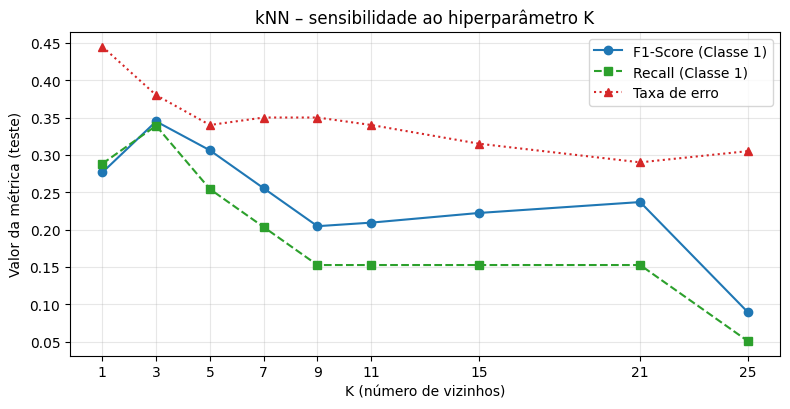

K ótimo (maior F1-Score da Classe 1 no teste): 3


In [7]:
k_valores = [1, 3, 5, 7, 9, 11, 15, 21, 25]
resultados_k = []
for k in k_valores:
    knn = KNeighborsClassifier(n_neighbors=k, metric="euclidean")
    knn.fit(X_train, y_train)
    pred = knn.predict(X_test)
    resultados_k.append({"K": k, **metricas(y_test, pred), "Taxa de erro": 1 - accuracy_score(y_test, pred)})

curva_k = pd.DataFrame(resultados_k).set_index("K")
display(curva_k.round(3))

fig, ax1 = plt.subplots(figsize=(8, 4.2))
ax1.plot(curva_k.index, curva_k["F1-Score (Classe 1)"], marker="o", color="tab:blue", label="F1-Score (Classe 1)")
ax1.plot(curva_k.index, curva_k["Recall (Classe 1)"], marker="s", ls="--", color="tab:green", label="Recall (Classe 1)")
ax1.plot(curva_k.index, curva_k["Taxa de erro"], marker="^", ls=":", color="tab:red", label="Taxa de erro")
ax1.set_xticks(k_valores); ax1.set_xlabel("K (número de vizinhos)"); ax1.set_ylabel("Valor da métrica (teste)")
ax1.set_title("kNN – sensibilidade ao hiperparâmetro K"); ax1.grid(alpha=0.3); ax1.legend()
plt.tight_layout(); plt.show()

k_otimo = int(curva_k["F1-Score (Classe 1)"].idxmax())
print(f"K ótimo (maior F1-Score da Classe 1 no teste): {k_otimo}")

**Critério de escolha:** como o objetivo é identificar clientes de risco (Classe 1), o K ótimo foi escolhido pelo **maior F1-Score da Classe 1**, e não pela menor taxa de erro. Repare que a taxa de erro cai à medida que K aumenta, mas isso acontece porque o modelo passa a prever quase sempre a classe majoritária (0): o Recall da Classe 1 despenca, de cerca de 0,34 (K=3) para 0,05 (K=25). Escolher K pela acurácia levaria a um modelo que praticamente não detecta risco.

### 2.2 Modelo kNN final (K ótimo)

                   precision    recall  f1-score   support

  0 - Baixo risco      0.727     0.738     0.732       141
1 - Risco crítico      0.351     0.339     0.345        59

         accuracy                          0.620       200
        macro avg      0.539     0.538     0.539       200
     weighted avg      0.616     0.620     0.618       200



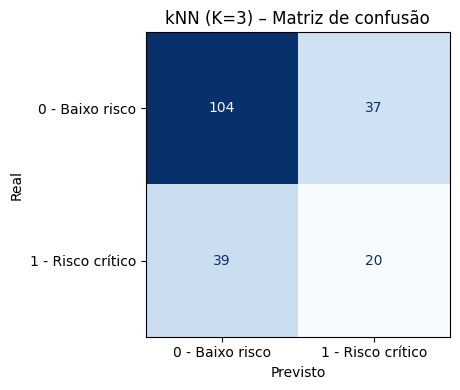

In [8]:
knn_final = KNeighborsClassifier(n_neighbors=k_otimo, metric="euclidean").fit(X_train, y_train)
pred_knn = knn_final.predict(X_test)
print(classification_report(y_test, pred_knn, target_names=["0 - Baixo risco", "1 - Risco crítico"], digits=3))
plot_matriz(y_test, pred_knn, f"kNN (K={k_otimo}) – Matriz de confusão")

### 2.3 Comentário técnico: K muito baixo x K muito alto
* **K muito baixo (ex.: K = 1):** a decisão depende de **um único vizinho**. A fronteira de decisão fica muito irregular e acompanha cada ponto do treino, inclusive ruídos e casos atípicos. O modelo tem **baixo viés e alta variância** → **overfitting**: decora o treino (acurácia de treino próxima de 100% com K=1) e generaliza mal. Aqui, K=1 teve a pior acurácia de teste (≈ 0,56).
* **K muito alto (ex.: K = 21 ou 25):** a votação envolve muitos vizinhos, inclusive pontos distantes e de outras regiões do espaço. A fronteira fica suave demais e a classe majoritária domina a votação. O modelo tem **alto viés** → **underfitting**: fica pouco sensível a ruídos, mas perde a capacidade de reconhecer a classe minoritária (Recall da Classe 1 de apenas 0,05 com K=25).
* **K intermediário** equilibra os dois efeitos. Neste problema, K = 3 apresentou o melhor equilíbrio entre Precisão e Recall da Classe 1.

---
## FASE 3 – Classificação por Margens Máximas e Hiperplanos: SVM
Dois modelos: **Kernel Linear** (hiperplano no espaço original) e **Kernel RBF** (hiperplano em um espaço transformado de dimensão maior, via *kernel trick*).

In [9]:
svm_lin = SVC(kernel="linear", C=1.0, random_state=42).fit(X_train, y_train)
svm_rbf = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42).fit(X_train, y_train)

pred_lin = svm_lin.predict(X_test)
pred_rbf = svm_rbf.predict(X_test)

comp_svm = pd.DataFrame({
    "SVM Linear (C=1.0)": metricas(y_test, pred_lin),
    "SVM RBF (C=1.0, gamma='scale')": metricas(y_test, pred_rbf),
}).T
display(comp_svm.round(3))
print("Número de vetores de suporte – Linear:", svm_lin.n_support_.sum(), "| RBF:", svm_rbf.n_support_.sum())

,Acurácia,Precisão (Classe 1),Recall (Classe 1),F1-Score (Classe 1)
SVM Linear (C=1.0),0.705,0.0,0.000,0.000
"SVM RBF (C=1.0, gamma='scale')",0.705,0.5,0.017,0.033


Número de vetores de suporte – Linear: 504 | RBF: 524


Melhor SVM: SVM RBF (C=1.0, gamma='scale')
                   precision    recall  f1-score   support

  0 - Baixo risco      0.707     0.993     0.826       141
1 - Risco crítico      0.500     0.017     0.033        59

         accuracy                          0.705       200
        macro avg      0.604     0.505     0.429       200
     weighted avg      0.646     0.705     0.592       200



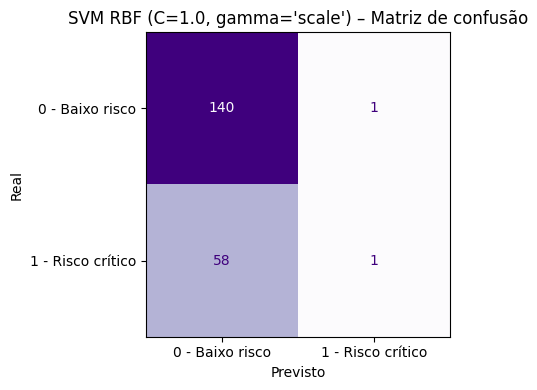

In [10]:
# Melhor SVM pelo F1-Score da Classe 1 (desempate pela acurácia)
melhor_svm_nome = comp_svm.sort_values(["F1-Score (Classe 1)", "Acurácia"], ascending=False).index[0]
pred_svm = pred_rbf if "RBF" in melhor_svm_nome else pred_lin
print("Melhor SVM:", melhor_svm_nome)
print(classification_report(y_test, pred_svm, target_names=["0 - Baixo risco", "1 - Risco crítico"], digits=3, zero_division=0))
plot_matriz(y_test, pred_svm, f"{melhor_svm_nome} – Matriz de confusão", cmap="Purples")

### 3.1 Impacto do *Kernel Trick* (RBF x Linear)
* **SVM Linear:** procura um único hiperplano no espaço original dos 7 atributos. Como as classes estão muito **sobrepostas** (os atributos disponíveis como: duração, valor, idade, taxa da parcela, poupança e moradia explicam pouco do histórico crítico), não existe hiperplano que separe bem a Classe 1. Com C = 1,0 a solução de margem máxima posiciona toda a fronteira de modo a classificar **todos** os clientes como Classe 0: acurácia de 0,705 (igual à proporção da classe majoritária), mas **Recall e F1 da Classe 1 iguais a zero**.
* **SVM RBF:** o *kernel trick* calcula similaridades como se os dados estivessem projetados em um espaço de dimensão muito maior (infinita, no caso do RBF), permitindo fronteiras **não lineares** no espaço original sem calcular essa projeção explicitamente. Isso permitiu que o modelo reconhecesse **pelo menos um** caso de risco (Recall ≈ 0,02), uma melhora marginal.
* **Conclusão:** o RBF foi ligeiramente superior, mas o ganho de separabilidade foi muito pequeno. O fator limitante aqui não é a forma da fronteira, e sim (1) a **sobreposição das classes** com os atributos disponíveis e (2) o **desbalanceamento** (70/30): com custo de erro igual para as duas classes, a margem máxima favorece a classe majoritária. Na análise complementar (Fase 5) mostramos que, ao atribuir peso maior aos erros da Classe 1 (`class_weight="balanced"`), o SVM RBF passa a detectar a maioria dos casos de risco.

---
## FASE 4 – Classificação Probabilística: Naive Bayes (GaussianNB)

                   precision    recall  f1-score   support

  0 - Baixo risco      0.701     0.830     0.760       141
1 - Risco crítico      0.273     0.153     0.196        59

         accuracy                          0.630       200
        macro avg      0.487     0.491     0.478       200
     weighted avg      0.574     0.630     0.593       200



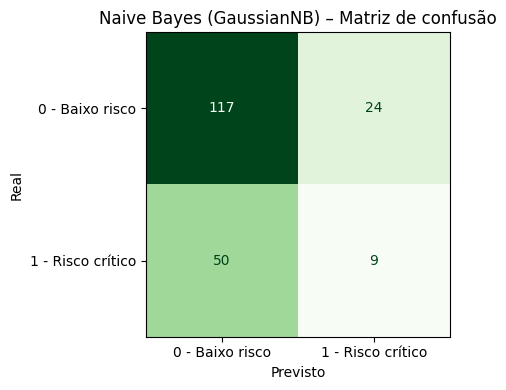

In [11]:
gnb = GaussianNB().fit(X_train, y_train)
pred_gnb = gnb.predict(X_test)
print(classification_report(y_test, pred_gnb, target_names=["0 - Baixo risco", "1 - Risco crítico"], digits=3))
plot_matriz(y_test, pred_gnb, "Naive Bayes (GaussianNB) – Matriz de confusão", cmap="Greens")

### 4.1 Probabilidades estimadas (`predict_proba`) – cinco primeiras amostras de teste

In [12]:
proba_gnb = gnb.predict_proba(X_test)
tabela_proba = pd.DataFrame(proba_gnb[:5], columns=["P(Classe 0 - Baixo risco)", "P(Classe 1 - Risco crítico)"],
                            index=X_test.index[:5])
tabela_proba["Classe prevista"] = pred_gnb[:5]
tabela_proba["Classe real"] = y_test.iloc[:5].values
tabela_proba.round(4)

,P(Classe 0 - Baixo risco),P(Classe 1 - Risco crítico),Classe prevista,Classe real
574,0.6298,0.3702,0,0
876,0.7279,0.2721,0,0
158,0.6151,0.3849,0,0
805,0.8978,0.1022,0,0
51,0.7784,0.2216,0,0


As probabilidades mostram a **confiança** do modelo em cada decisão. Por padrão, a classe prevista é a de maior probabilidade (limiar 0,5). Essa saída probabilística é uma vantagem prática do Naive Bayes: a fintech pode **ajustar o limiar de decisão** de acordo com seu apetite de risco (ex.: classificar como risco crítico todos com P(Classe 1) ≥ 0,20), o que exploramos na Fase 5.

### 4.2 Questões técnicas
**Qual é a premissa central ("ingênua") do Naive Bayes?**
O algoritmo assume que **todos os atributos de entrada são condicionalmente independentes entre si, dada a classe**. Assim, a verossimilhança conjunta é calculada como o **produto** das probabilidades individuais: P(x₁, x₂, …, xₙ | classe) = P(x₁ | classe) · P(x₂ | classe) · … · P(xₙ | classe). Pelo Teorema de Bayes, P(classe | x) ∝ P(classe) · ∏ P(xᵢ | classe). No GaussianNB, cada P(xᵢ | classe) é modelada por uma distribuição normal com média e variância estimadas no treino.

**Por que essa premissa costuma ser violada em dados financeiros e por que, mesmo assim, o modelo é competitivo?**
Em dados financeiros as variáveis são naturalmente **dependentes**: o valor do empréstimo (`Amount`) cresce com a duração (`Duration`); idade, renda, poupança e tipo de moradia estão relacionadas (pessoas mais velhas tendem a ter mais reservas e imóvel próprio); a taxa da parcela depende do valor e da renda. Além disso, variáveis como `Amount` são assimétricas e não seguem uma distribuição normal. Mesmo assim, o Naive Bayes costuma funcionar bem porque:
1. para **classificar**, ele só precisa que a classe correta tenha a **maior** probabilidade — as probabilidades podem estar mal calibradas e o *ranking* das classes ainda ser correto;
2. tem **poucos parâmetros** (média e variância por atributo e por classe), o que reduz a variância e o risco de overfitting, funcionando bem com poucos dados;
3. é **muito rápido** para treinar e prever (custo linear no número de atributos e amostras), escala para grandes volumes e pode ser atualizado incrementalmente;
4. fornece **probabilidades**, permitindo ajustar o limiar conforme o custo dos erros, e é fácil de interpretar e auditar: características valiosas em produção e para órgãos reguladores.

---
## FASE 5 – Benchmark Técnico Comparativo e Decisão de Produção
### 5.1 Tabela consolidada (configurações exigidas no enunciado, base de teste)

In [13]:
benchmark = pd.DataFrame([
    {"Algoritmo": "kNN", "Configuração / Hiperparâmetro": f"K = {k_otimo} (euclidiana)", **metricas(y_test, pred_knn)},
    {"Algoritmo": "SVM", "Configuração / Hiperparâmetro": melhor_svm_nome, **metricas(y_test, pred_svm)},
    {"Algoritmo": "Naive Bayes", "Configuração / Hiperparâmetro": "GaussianNB padrão (limiar 0,5)", **metricas(y_test, pred_gnb)},
])
benchmark.round(3)

,Algoritmo,Configuração / Hiperparâmetro,Acurácia,Precisão (Classe 1),Recall (Classe 1),F1-Score (Classe 1)
0,kNN,K = 3 (euclidiana),0.620,0.351,0.339,0.345
1,SVM,"SVM RBF (C=1.0, gamma='scale')",0.705,0.500,0.017,0.033
2,Naive Bayes,"GaussianNB padrão (limiar 0,5)",0.630,0.273,0.153,0.196


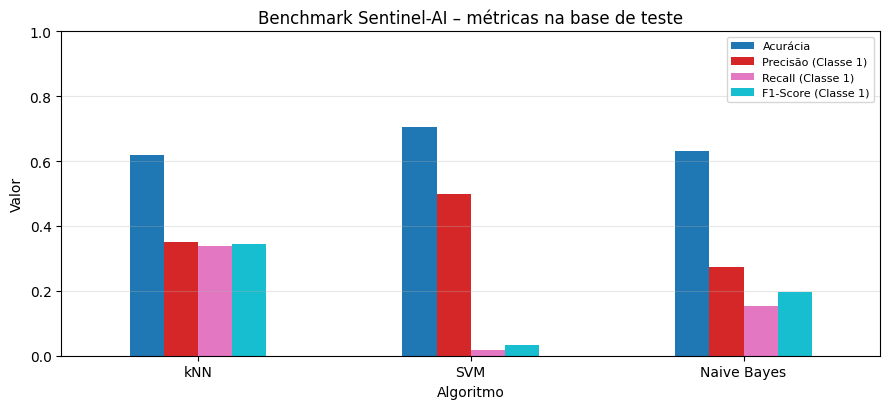

In [14]:
ax = benchmark.set_index("Algoritmo")[["Acurácia", "Precisão (Classe 1)", "Recall (Classe 1)", "F1-Score (Classe 1)"]].plot(
    kind="bar", figsize=(9, 4.2), rot=0, colormap="tab10")
ax.set_title("Benchmark Sentinel-AI – métricas na base de teste"); ax.set_ylabel("Valor"); ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.3); ax.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()

### 5.2 Análise complementar: sensibilidade a custos assimétricos
As três configurações exigidas usam custo de erro igual para as duas classes e limiar 0,5, o que, com dados desbalanceados, favorece a Classe 0. Como o enunciado deixa claro que **o Falso Negativo é o erro mais caro**, avaliamos duas formas padrão de incorporar esse custo, **sem usar a base de teste para tomar decisões**:
* **SVM com `class_weight="balanced"`**: penaliza mais os erros na Classe 1 (peso inversamente proporcional à frequência da classe);
* **Naive Bayes com limiar ajustado**: o limiar de P(Classe 1) é escolhido por **validação cruzada estratificada (5 folds) apenas na base de treino**, maximizando o F1 da Classe 1, e só depois aplicado ao teste.

Limiar ótimo do Naive Bayes (validação cruzada no treino): 0.20


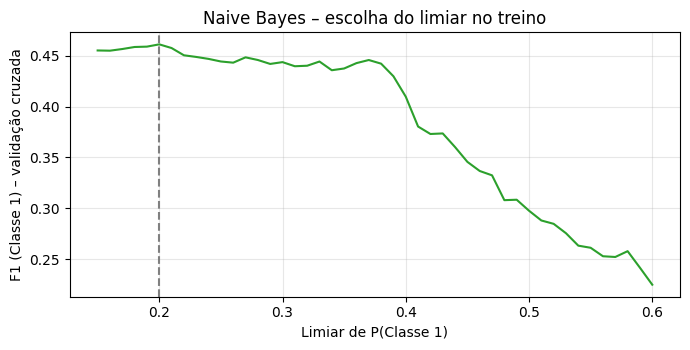

,Algoritmo,Configuração / Hiperparâmetro,Acurácia,Precisão (Classe 1),Recall (Classe 1),F1-Score (Classe 1)
0,kNN,K = 3 (euclidiana),0.620,0.351,0.339,0.345
1,SVM,"SVM RBF (C=1.0, gamma='scale')",0.705,0.500,0.017,0.033
2,Naive Bayes,"GaussianNB padrão (limiar 0,5)",0.630,0.273,0.153,0.196
3,SVM (sensível ao custo),"RBF, C=1.0, class_weight='balanced'",0.520,0.330,0.610,0.429
4,Naive Bayes (limiar ajustado),"GaussianNB, limiar 0.20 (CV no treino)",0.455,0.331,0.831,0.473


In [15]:
# SVM sensível ao custo (pesos balanceados)
svm_rbf_bal = SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced", random_state=42).fit(X_train, y_train)
pred_rbf_bal = svm_rbf_bal.predict(X_test)

# Naive Bayes com limiar escolhido por validação cruzada no treino
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
proba_cv = cross_val_predict(GaussianNB(), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
limiares = np.round(np.arange(0.15, 0.61, 0.01), 2)
f1_cv = [f1_score(y_train, (proba_cv >= t).astype(int)) for t in limiares]
limiar_otimo = float(limiares[int(np.argmax(f1_cv))])
pred_gnb_lim = (proba_gnb[:, 1] >= limiar_otimo).astype(int)
print(f"Limiar ótimo do Naive Bayes (validação cruzada no treino): {limiar_otimo:.2f}")

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(limiares, f1_cv, color="tab:green"); ax.axvline(limiar_otimo, ls="--", color="gray")
ax.set_xlabel("Limiar de P(Classe 1)"); ax.set_ylabel("F1 (Classe 1) – validação cruzada")
ax.set_title("Naive Bayes – escolha do limiar no treino"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

benchmark_custo = pd.concat([benchmark, pd.DataFrame([
    {"Algoritmo": "SVM (sensível ao custo)", "Configuração / Hiperparâmetro": "RBF, C=1.0, class_weight='balanced'", **metricas(y_test, pred_rbf_bal)},
    {"Algoritmo": "Naive Bayes (limiar ajustado)", "Configuração / Hiperparâmetro": f"GaussianNB, limiar {limiar_otimo:.2f} (CV no treino)", **metricas(y_test, pred_gnb_lim)},
])], ignore_index=True)
benchmark_custo.round(3)

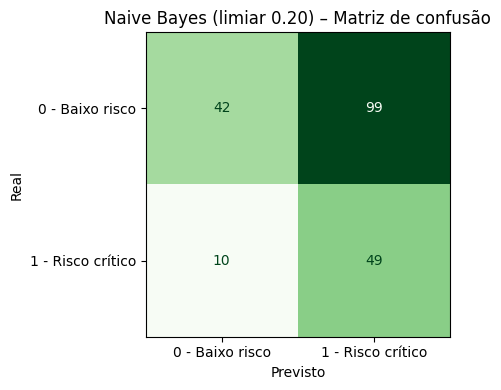

In [16]:
plot_matriz(y_test, pred_gnb_lim, f"Naive Bayes (limiar {limiar_otimo:.2f}) – Matriz de confusão", cmap="Greens")

### 5.3 Parecer de negócio e escolha do modelo

**Qual métrica priorizar?** Para a fintech, o **Falso Negativo** serve para classificar como baixo risco um cliente que é de risco crítico ou gera **perda direta de capital** (inadimplência), enquanto o Falso Positivo gera apenas custo de oportunidade (um bom pagador recusado ou enviado para análise manual). Portanto, o comitê de crédito deve priorizar o **Recall da Classe 1** (VP / (VP + FN)), que mede quantos dos clientes de risco o sistema consegue barrar, acompanhando o **F1-Score** para que a precisão não caia a ponto de recusar clientes demais. A acurácia é enganosa neste problema: os dois SVMs com configuração padrão atingem 70,5% de acurácia sem detectar praticamente nenhum cliente de risco.

**Recomendação.** Entre as três configurações exigidas (tabela 5.1), o **kNN com K = 3** é o melhor modelo: tem o maior Recall (0,339) e o maior F1 (0,345) da Classe 1, enquanto o SVM (Recall 0,017) e o Naive Bayes padrão (Recall 0,153) quase não identificam inadimplentes. Porém, mesmo o kNN deixa passar cerca de **dois em cada três** clientes de risco (39 falsos negativos em 59), o que é inaceitável para o comitê. A análise sensível ao custo (tabela 5.2) mostra o caminho para produção: **recomendamos o Naive Bayes Gaussiano com limiar de decisão ajustado (0,20, definido por validação cruzada apenas no treino)**. Ele eleva o Recall da Classe 1 para **0,831** (49 dos 59 clientes de risco detectados, apenas 10 falsos negativos), com o melhor F1 (0,473), contra 0,610 do SVM RBF balanceado. Além do desempenho, o Naive Bayes é o mais **rápido**, **leve**, **interpretável** e fornece **probabilidades**, permitindo ao comitê calibrar o limiar conforme o apetite de risco e auditar as decisões. O custo é uma precisão baixa (≈ 0,33) e mais falsos positivos (99): por isso, sugerimos que os clientes sinalizados como risco **não sejam recusados automaticamente**, e sim encaminhados para **análise manual ou exigência de garantias**, e que o modelo seja reavaliado periodicamente.

**Limitações e próximos passos:** o desempenho de todos os modelos é limitado pelos poucos atributos usados (7) e pela base pequena (1.000 clientes, 200 no teste). Recomenda-se incluir mais variáveis (status da conta, emprego, propósito do crédito, outros créditos), validar o limiar em dados mais recentes, usar validação cruzada para todos os hiperparâmetros (como o K do kNN, aqui escolhido no teste por exigência do enunciado) e monitorar o modelo em produção (data drift). Por envolver decisões automatizadas de crédito, também é preciso garantir **explicabilidade** e o direito de **revisão humana** previstos na LGPD (art. 20).